# MNIST from scratch

A handwritten-digit classifier built with **only NumPy** — no PyTorch, no
TensorFlow, no autograd. Every forward pass, gradient, and weight update is
written out so you can read the mathematics directly in the code.

This notebook walks through the whole pipeline that lives in the `.py` files
next to it:

1. Load and inspect the data
2. Build the multi-layer perceptron (MLP)
3. Verify backpropagation against numerical gradients
4. Train with mini-batch gradient descent
5. Evaluate on the test set and look at the mistakes
6. Inspect a single prediction

The model is:

```
784 inputs -> Linear -> ReLU -> Linear -> ReLU -> 10 outputs -> softmax + cross-entropy
```


In [11]:
import os
import sys

# The notebook lives in notebooks/; the project modules live in the repo root.
for path in (os.getcwd(),
             os.path.abspath(os.path.join(os.getcwd(), os.pardir))):
    if os.path.exists(os.path.join(path, "network.py")) and path not in sys.path:
        sys.path.insert(0, path)

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import data
from network import MLP, make_optimizer

print("numpy", np.__version__)

numpy 2.4.6


## 1. The data

MNIST is 70,000 grayscale 28x28 images of digits (0–9): 60,000 train, 10,000
test. `data.load()` downloads and caches the archive, then applies three
preprocessing steps that matter a lot for training:

1. **Flatten** each 28x28 image into a 784-vector (the first layer is a matrix
   multiply).
2. **Scale** pixels from `[0, 255]` to `[0, 1]`. Gradient descent moves in
   proportion to the input magnitude, so comparable inputs make the loss
   surface far easier to descend.
3. **One-hot encode** the labels: `3 -> [0,0,0,1,0,0,0,0,0,0]`, which pairs
   with the softmax cross-entropy loss.

In [12]:
# Training arrays: flattened, scaled to [0,1], one-hot labels.
(x_train, y_train), (x_test, y_test) = data.load()
# Extra views kept in image / integer-label form for plotting.
(x_train_img, y_train_lbl), (x_test_img, y_test_lbl) = data.load(
    flatten=False, one_hot_labels=False)

print("train:", x_train.shape, y_train.shape)
print("test: ", x_test.shape, y_test.shape)
print("pixel range:", x_train.min(), "-", x_train.max())

train: (60000, 784) (60000, 10)
test:  (10000, 784) (10000, 10)
pixel range: 0.0 - 1.0


### A look at the digits

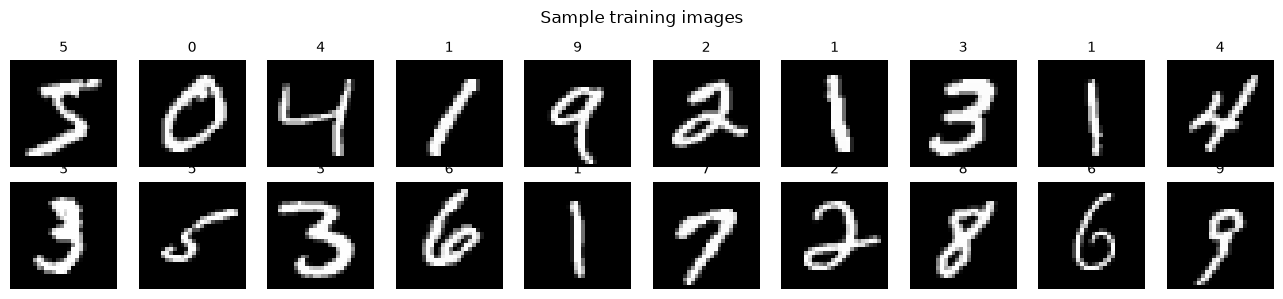

In [13]:
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for ax, img, label in zip(axes.ravel(), x_train_img[:20], y_train_lbl[:20]):
    ax.imshow(img, cmap="gray")
    ax.set_title(int(label), fontsize=10)
    ax.axis("off")
fig.suptitle("Sample training images")
fig.tight_layout()
plt.show()

## 2. The network

`network.py` defines three layers and wires them into an `MLP`:

- **`Linear`** — `Z = XW + b`, with He initialisation
  (`std = sqrt(2 / fan_in)`) so activation variance stays roughly constant
  through the stack.
- **`ReLU`** — `max(0, Z)`. Without this non-linearity, stacked linear layers
  would collapse into a single linear layer.
- **`SoftmaxCrossEntropy`** — turns logits into probabilities and measures the
  loss, with the famously clean gradient `dL/dZ = (p - y) / B`.

`MLP([784, 256, 128, 10])` builds `Linear+ReLU -> Linear+ReLU -> Linear(10)`.

In [14]:
model = MLP([784, 256, 128, 10], seed=0)

for layer in model.layers:
    print(type(layer).__name__)

n_params = sum(l.W.size + l.b.size for l in model.weight_layers)
print(f"\ntrainable parameters: {n_params:,}")

Linear
ReLU
Linear
ReLU
Linear

trainable parameters: 235,146


## 3. Gradient check

Before trusting any training run, we should confirm the hand-written backward
pass is correct. The definition of a derivative gives us a brute-force
estimate:

```
dL/dw  ~=  (L(w + eps) - L(w - eps)) / (2 * eps)
```

for a tiny `eps`. If that matches backprop, the chain rule implementation is
right. We run the check in **float64**, because central differences divide a
tiny numerator by `2*eps` and float32 round-off would swamp the signal.

In [15]:
gmodel = MLP([20, 16, 12, 5], seed=0)
for layer in gmodel.weight_layers:
    layer.W = layer.W.astype(np.float64)
    layer.b = layer.b.astype(np.float64)

grng = np.random.default_rng(1)
x = grng.normal(size=(8, 20))
y = np.zeros((8, 5))
y[np.arange(8), grng.integers(0, 5, 8)] = 1.0

gmodel.loss(x, y)      # forward, caches activations
gmodel.backward()      # fills layer.dW / layer.db


def num_grad(i, name, idx, eps=1e-5):
    """Central-difference estimate of dL/d(param[idx]) for layer i."""
    param = getattr(gmodel.weight_layers[i], name).reshape(-1)
    orig = param[idx]
    param[idx] = orig + eps
    lp = gmodel.loss(x, y)
    param[idx] = orig - eps
    lm = gmodel.loss(x, y)
    param[idx] = orig
    return (lp - lm) / (2 * eps)


worst = 0.0
for i, layer in enumerate(gmodel.weight_layers):
    for name, grad in (("W", layer.dW), ("b", layer.db)):
        flat = grad.reshape(-1)
        for idx in range(0, flat.size, max(1, flat.size // 3)):
            ng = num_grad(i, name, idx)
            ag = float(flat[idx])
            worst = max(worst, abs(ag - ng) / max(1e-8, abs(ag) + abs(ng)))

print(f"max relative error: {worst:.2e}")
print("PASS" if worst < 1e-4 else "FAIL")

max relative error: 9.51e-09
PASS


## 4. Training

The training loop is classic mini-batch SGD:

```
for each epoch:
    shuffle the training data
    for each mini-batch:
        forward  -> logits
        loss     -> softmax cross-entropy
        backward -> gradients
        step     -> nudge the weights down the gradient
```

A batch of ~128 gives a good estimate of the true gradient at a fraction of
the cost of the full 60,000, and the noise even helps escape shallow traps.
Here we use **Adam**, which takes per-parameter adaptive steps and converges
in a handful of epochs.

In [16]:
EPOCHS = 100
BATCH_SIZE = 128
LR = 1e-3
OPTIMIZER = "adam"

model = MLP([784, 256, 128, 10], seed=0)
optimizer = make_optimizer(OPTIMIZER, model.weight_layers, lr=LR)
rng = np.random.default_rng(0)

history = {"train_loss": [], "train_acc": [], "test_acc": []}

for epoch in range(1, EPOCHS + 1):
    idx = rng.permutation(len(x_train))
    running, seen = 0.0, 0
    for start in range(0, len(x_train), BATCH_SIZE):
        b = idx[start:start + BATCH_SIZE]
        loss = model.loss(x_train[b], y_train[b])   # forward + loss
        model.backward()                            # backprop
        optimizer.step()                            # update weights
        running += loss * len(b)
        seen += len(b)

    train_loss = running / seen
    train_acc = model.accuracy(x_train, y_train)
    test_acc = model.accuracy(x_test, y_test)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)
    print(f"epoch {epoch}/{EPOCHS}  loss {train_loss:.4f}  "
          f"train_acc {train_acc * 100:5.2f}%  test_acc {test_acc * 100:5.2f}%")

epoch 1/100  loss 0.2715  train_acc 96.54%  test_acc 96.18%
epoch 2/100  loss 0.1018  train_acc 98.13%  test_acc 97.22%
epoch 3/100  loss 0.0659  train_acc 98.71%  test_acc 97.59%
epoch 4/100  loss 0.0477  train_acc 99.04%  test_acc 97.67%
epoch 5/100  loss 0.0355  train_acc 99.25%  test_acc 97.83%
epoch 6/100  loss 0.0282  train_acc 99.41%  test_acc 98.02%
epoch 7/100  loss 0.0215  train_acc 99.06%  test_acc 97.36%
epoch 8/100  loss 0.0174  train_acc 99.52%  test_acc 97.77%
epoch 9/100  loss 0.0152  train_acc 99.25%  test_acc 97.63%
epoch 10/100  loss 0.0132  train_acc 99.52%  test_acc 97.95%
epoch 11/100  loss 0.0084  train_acc 99.68%  test_acc 97.93%
epoch 12/100  loss 0.0133  train_acc 99.65%  test_acc 97.88%
epoch 13/100  loss 0.0090  train_acc 99.64%  test_acc 97.78%
epoch 14/100  loss 0.0099  train_acc 99.78%  test_acc 97.99%
epoch 15/100  loss 0.0069  train_acc 99.72%  test_acc 97.95%
epoch 16/100  loss 0.0074  train_acc 99.91%  test_acc 98.23%
epoch 17/100  loss 0.0089  train_

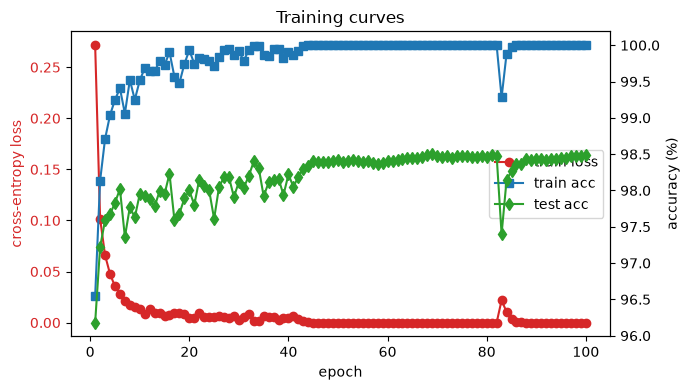

In [17]:
epochs = np.arange(1, len(history["train_loss"]) + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, history["train_loss"], "o-", color="tab:red", label="train loss")
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy loss", color="tab:red")
ax.tick_params(axis="y", labelcolor="tab:red")

ax2 = ax.twinx()
ax2.plot(epochs, np.array(history["train_acc"]) * 100, "s-",
         color="tab:blue", label="train acc")
ax2.plot(epochs, np.array(history["test_acc"]) * 100, "d-",
         color="tab:green", label="test acc")
ax2.set_ylabel("accuracy (%)")

lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], loc="center right")
ax.set_title("Training curves")
fig.tight_layout()
plt.show()

## 5. Evaluation

Inference is fully vectorised: passing the whole `(10000, 784)` test set does
all 10,000 predictions in one set of matrix multiplies.

In [18]:
probs = model.predict_proba(x_test)          # (10000, 10)
preds = probs.argmax(axis=1)

acc = (preds == y_test_lbl).mean()
print(f"test accuracy: {acc * 100:.2f}%")

print("\nper-class accuracy:")
for c in range(10):
    m = y_test_lbl == c
    print(f"  {c}: {(preds[m] == c).sum():>3}/{m.sum():<3} "
          f"{(preds[m] == c).mean() * 100:5.1f}%")

test accuracy: 98.49%

per-class accuracy:
  0: 975/980  99.5%
  1: 1131/1135  99.6%
  2: 1018/1032  98.6%
  3: 992/1010  98.2%
  4: 966/982  98.4%
  5: 869/892  97.4%
  6: 945/958  98.6%
  7: 1008/1028  98.1%
  8: 954/974  97.9%
  9: 991/1009  98.2%


### Where the model goes wrong

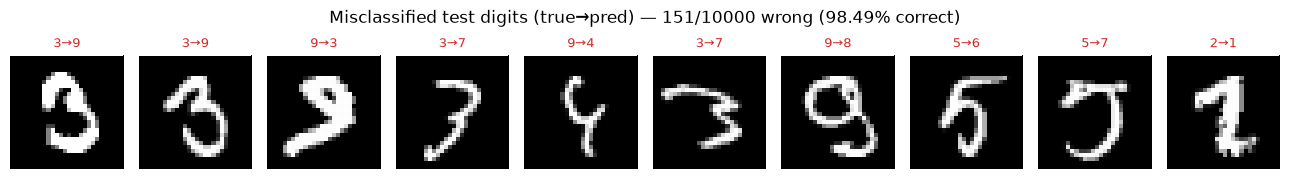

In [19]:
wrong = np.where(preds != y_test_lbl)[0]
rng = np.random.default_rng(0)
chosen = rng.choice(wrong, size=min(10, len(wrong)), replace=False)

fig, axes = plt.subplots(1, len(chosen), figsize=(13, 1.8))
for ax, i in zip(np.atleast_1d(axes), chosen):
    ax.imshow(x_test_img[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{y_test_lbl[i]}\u2192{preds[i]}", fontsize=9, color="tab:red")
    ax.axis("off")
fig.suptitle(f"Misclassified test digits (true\u2192pred) — "
             f"{len(wrong)}/{len(x_test)} wrong "
             f"({(1 - len(wrong) / len(x_test)) * 100:.2f}% correct)")
fig.tight_layout()
plt.show()

## 6. One prediction in detail

`predict_proba` applies a numerically stable softmax to the logits, giving a
full distribution over the ten digits for a single image.

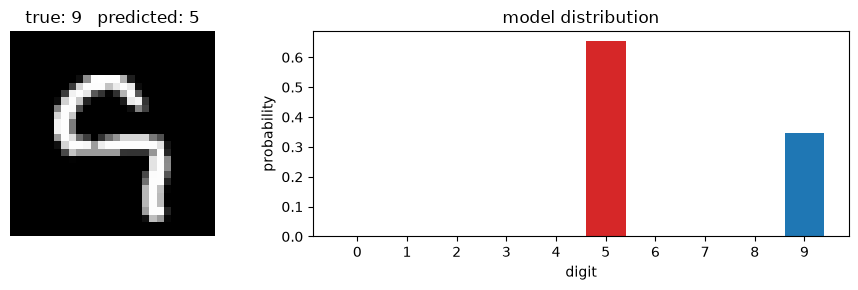

In [20]:
i = int(np.where(preds != y_test_lbl)[0][0])   # pick a mistake to inspect
p = model.predict_proba(x_test[i:i + 1])[0]

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(9, 3),
                                     gridspec_kw={"width_ratios": [1, 2]})
ax_img.imshow(x_test_img[i], cmap="gray", vmin=0, vmax=1)
ax_img.set_title(f"true: {y_test_lbl[i]}   predicted: {preds[i]}")
ax_img.axis("off")

ax_bar.bar(range(10), p, color=["tab:red" if c == preds[i] else "tab:blue"
                                 for c in range(10)])
ax_bar.set_xticks(range(10))
ax_bar.set_xlabel("digit")
ax_bar.set_ylabel("probability")
ax_bar.set_title("model distribution")
fig.tight_layout()
plt.show()

## Next steps

Ideas to extend the model (see the README for more):

- Add a `Dropout` layer between the hidden layers.
- Swap Adam for Nesterov momentum or a learning-rate schedule.
- Add a second hidden layer and study the bias/variance trade-off.
- Visualise the learned first-layer weights to see the features it picks up.
- Replace the MLP with a small convolutional network (a much bigger step).